# BrainScan AI — Brain Tumor Classification Using CNN

## Project objective

Develop a Convolutional Neural Network (CNN) to classify brain MRI images into four categories:

- Glioma tumor
- Meningioma tumor
- No tumor
- Pituitary tumor

The notebook covers dataset exploration, image preprocessing, model development, training, evaluation, and prediction.

**Important:** This is an educational AI project. Its predictions are not a substitute for professional medical diagnosis.

### Step 1: Import Libraries

Import the libraries needed for image processing, data visualization, CNN training, and evaluation.

In [6]:

import os
import time
import random
from pathlib import Path
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow:", tf.__version__)
print("OpenCV:", cv2.__version__)


TensorFlow: 2.22.0-rc0
OpenCV: 5.0.0


### Step 2: Dataset Path

Define the path to the dataset and verify that the folder exists.

In [7]:
DATA_DIR = Path("data/brain_mri/Data")

print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())

Dataset path: /home/lahcen404/Desktop/YouCode-Y2/BrainScanAI/notebooks/data/brain_mri/Data
Dataset exists: False


### Dataset Structure

Inspect the extracted dataset to identify the class folders and verify that each class contains images.

In [ ]:
print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())
print("Class folders:")

for folder in sorted(DATA_DIR.iterdir()):
    if folder.is_dir():
        image_count = sum(1 for file in folder.iterdir() if file.is_file())
        print(f"{folder.name}: {image_count} files")

Dataset exists: True
Class folders:
glioma: 1621 files
meningioma: 1645 files
notumor: 2000 files
pituitary: 1757 files


### Verify Image Files

Count files with supported image extensions in each class. This helps identify the dataset size and potential class imbalance before loading images.

In [ ]:
VALID_EXTENSIONS = {".jpeg", ".jpg", ".bmp", ".png"}

class_counts = {}

for class_name in sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()):
    class_dir = DATA_DIR / class_name

    image_files = [
        file for file in class_dir.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    ]

    class_counts[class_name] = len(image_files)

class_counts_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Number of Images"]
)

display(class_counts_df)

print("Total supported image files:", sum(class_counts.values()))

,Class,Number of Images
0,glioma,1621
1,meningioma,1645
2,notumor,2000
3,pituitary,1757


Total supported image files: 7023


### Class Distribution

Visualize the number of images in each class to check whether the dataset is balanced.

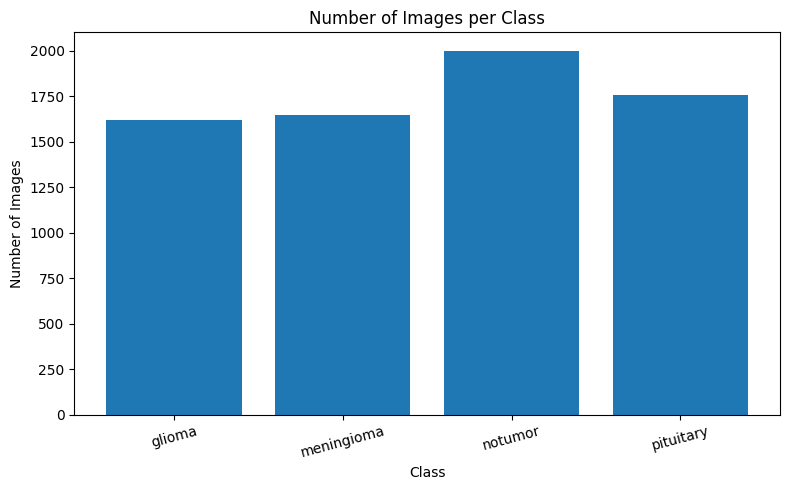

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Load and Resize Images

Read images from each class folder, resize them to 224 × 224 pixels, and store their corresponding labels. Keep images and labels aligned, and record files that fail to load.

In [ ]:
IMAGE_SIZE = (224, 224)
X = []
y = []
failed_images = []

for class_name in sorted(class_counts.keys()):
    class_dir = DATA_DIR / class_name

    for file in sorted(class_dir.iterdir()):
        if not file.is_file() or file.suffix.lower() not in VALID_EXTENSIONS:
            continue

        try:
            image = cv2.imread(str(file))

            if image is None:
                failed_images.append(str(file))
                continue

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, IMAGE_SIZE)

            X.append(image)
            y.append(class_name)

        except Exception as e:
            failed_images.append(str(file))
            print(f"Could not load {file.name}: {e}")

X = np.array(X, dtype=np.uint8)
y = np.array(y)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Failed images:", len(failed_images))
print("Unique labels:", np.unique(y))

Images shape: (7023, 224, 224, 3)
Labels shape: (7023,)
Failed images: 0
Unique labels: ['glioma' 'meningioma' 'notumor' 'pituitary']


##  Visualize Sample Images

Display sample MRI images with their corresponding class labels to verify that images were loaded correctly and that their labels match their content.

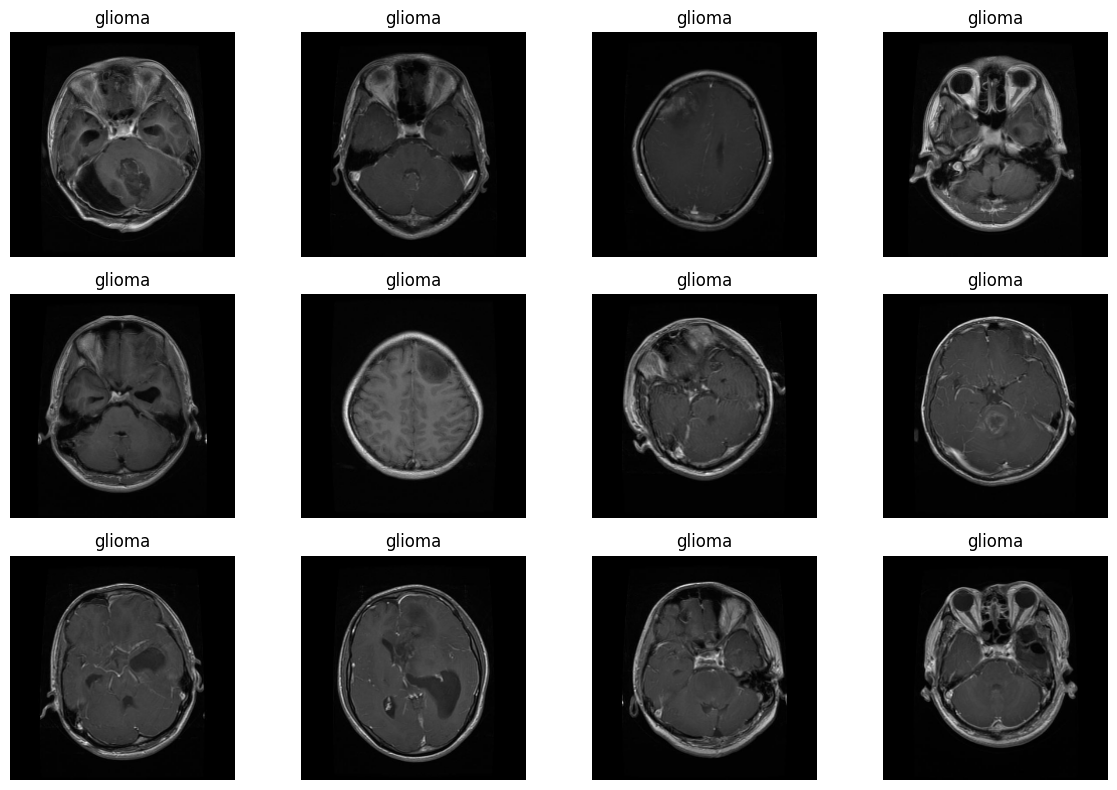

In [8]:
plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X[i])
    plt.title(y[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Encode Class Labels

Convert the categorical class labels into numerical values using `LabelEncoder`. Machine-learning models work with numerical targets, so this step prepares our labels for training.

In [9]:
label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)
print("Encoded labels:", np.unique(y_encoded))
print("First 10 labels:", y[:10])
print("First 10 encoded labels:", y_encoded[:10])

Classes: ['glioma' 'meningioma' 'notumor' 'pituitary']
Encoded labels: [0 1 2 3]
First 10 labels: ['glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma' 'glioma'
 'glioma' 'glioma']
First 10 encoded labels: [0 0 0 0 0 0 0 0 0 0]


## Train-Test Split

Split the dataset into training and testing sets. The training set is used to teach the CNN, while the testing set evaluates how well it performs on unseen images.

We use an 80/20 split and `stratify=y_encoded` to preserve approximately the same class proportions in both sets.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Train-Test Split complete!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train count:", len(y_train))
print("y_test count:", len(y_test))

Train-Test Split complete!
X_train shape: (5618, 224, 224, 3)
X_test shape: (1405, 224, 224, 3)
y_train count: 5618
y_test count: 1405


In [15]:
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

def prepare_batch(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_train_part, y_train_part))
    .shuffle(2000)
    .batch(8)
    .map(prepare_batch, num_parallel_calls=1)
    .prefetch(1)
)

val_ds = (
    tf.data.Dataset
    .from_tensor_slices((X_val, y_val))
    .batch(8)
    .map(prepare_batch, num_parallel_calls=1)
    .prefetch(1)
)

## Image Normalization

Normalize pixel values from the range 0–255 to the range 0–1 by dividing by 255.0.

This helps the CNN train more efficiently because the input values have a smaller, consistent scale. We apply the same transformation to both training and testing images.

In [ ]:
#X_train = X_train.astype("float32") / 255.0
#X_test = X_test.astype("float32") /255.0

#print("X_train range:", X_train.min(), "to", X_train.max())
#print("X_test range:", X_test.min(), "to", X_test.max())
#print("X_train dtype:", X_train.dtype)
#print("X_test dtype:", X_test.dtype)

## Random Sample Visualization

Display randomly selected MRI images from the training set, including their class labels. This helps us visually inspect the dataset and verify that all four classes are represented.

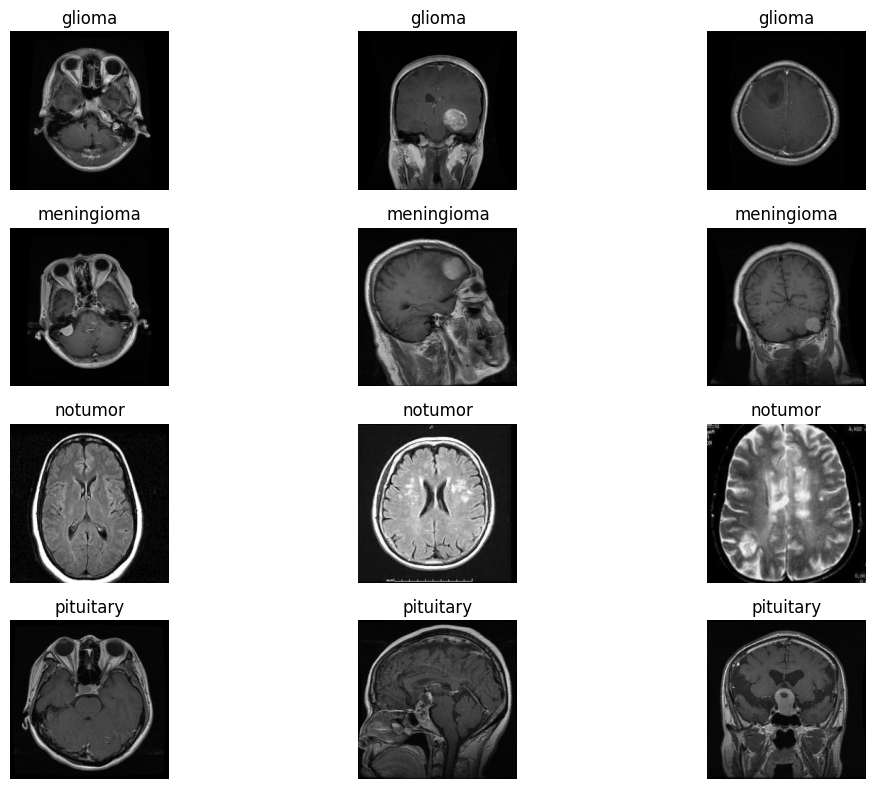

In [16]:
class_names = label_encoder.classes_

plt.figure(figsize=(12, 8))

for class_id, class_name in enumerate(class_names):
    indices = np.where(y_train == class_id)[0]
    random_indices = random.sample(list(indices), 3)

    for j, idx in enumerate(random_indices):
        plt.subplot(4, 3, class_id * 3 + j + 1)
        plt.imshow(X_train[idx])
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

## Training and Testing Class Distribution

Compare the number of images from each class in the training and testing sets. This verifies that stratified splitting preserved the class proportions and helps identify any imbalance that could affect model training.

,Class,Training Images,Testing Images
0,glioma,1297,324
1,meningioma,1316,329
2,notumor,1600,400
3,pituitary,1405,352


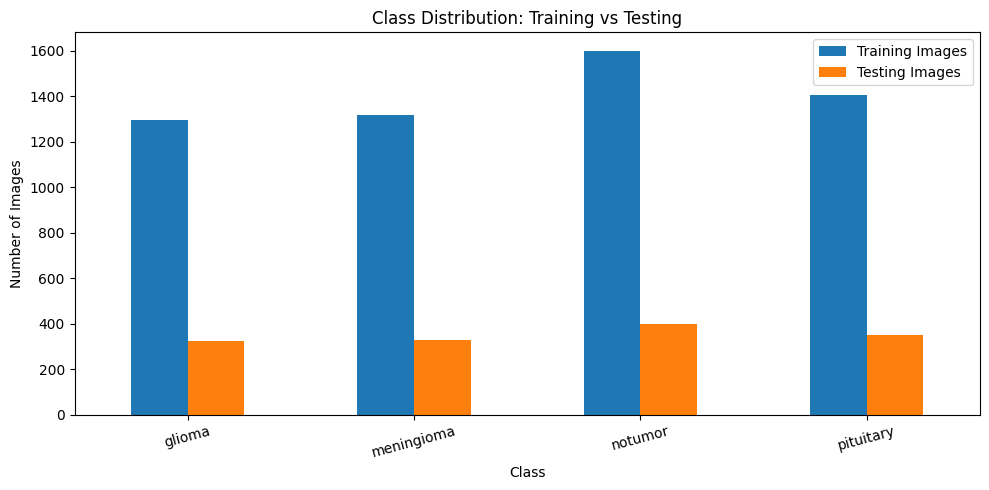

In [17]:
train_counts = Counter(y_train)
test_counts = Counter(y_test)

distribution_df = pd.DataFrame({
    "Class": class_names,
    "Training Images": [train_counts[i] for i in range(len(class_names))],
    "Testing Images": [test_counts[i] for i in range(len(class_names))]
})

display(distribution_df)

distribution_df.set_index("Class").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Class Distribution: Training vs Testing")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## CNN Architecture

Build a Convolutional Neural Network (CNN) using convolution, pooling, dropout, and dense layers.

- **Conv2D:** learns visual features such as edges, shapes, and patterns.
- **MaxPooling2D:** reduces feature-map dimensions while retaining important information.
- **Dropout:** randomly disables some neurons during training to help reduce overfitting.
- **Flatten:** converts feature maps into a one-dimensional vector.
- **Dense:** combines learned features to classify the MRI image.

The input shape is 224 × 224 × 3, and the output contains four class scores.

### Train the moodel

In [23]:
for images, labels in train_ds.take(1):
    print("Training images:", images.shape)
    print("Training pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))
    print("Training labels:", labels[:10].numpy())

for images, labels in val_ds.take(1):
    print("Validation images:", images.shape)
    print("Validation pixel range:", float(tf.reduce_min(images)),
          "to", float(tf.reduce_max(images)))

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())

Training images: (8, 224, 224, 3)
Training pixel range: 0.0 to 1.0
Training labels: [0 1 1 3 2 3 3 1]
Validation images: (8, 224, 224, 3)
Validation pixel range: 0.0 to 1.0
Training batches: 562
Validation batches: 141


In [24]:
tf.keras.backend.clear_session()

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/brainscan_model_v2.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[checkpoint, early_stopping]
)

Epoch 1/20
562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6036 - loss: 0.9682
Epoch 1: val_loss improved from None to 0.39445, saving model to /content/brainscan_model_v2.keras

Epoch 1: finished saving model to /content/brainscan_model_v2.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 27s 35ms/step - accuracy: 0.6992 - loss: 0.7735 - val_accuracy: 0.8603 - val_loss: 0.3945
Epoch 2/20
562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8355 - loss: 0.4326
Epoch 2: val_loss improved from 0.39445 to 0.26067, saving model to /content/brainscan_model_v2.keras

Epoch 2: finished saving model to /content/brainscan_model_v2.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 13s 23ms/step - accuracy: 0.8485 - loss: 0.4082 - val_accuracy: 0.9066 - val_loss: 0.2607
Epoch 3/20
561/562 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8943 - loss: 0.2908
Epoch 3: val_loss improved from 0.26067 to 0.24664, saving model to /content/brainscan_model_v2.keras

Epoch 3: finished saving model to /content/brainscan_model_

176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.9281 - loss: 0.2190
Test Loss: 0.2190
Test Accuracy: 92.81%
176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.88      0.92       324
  meningioma       0.86      0.85      0.86       329
     notumor       0.98      0.97      0.97       400
   pituitary       0.91      1.00      0.95       352

    accuracy                           0.93      1405
   macro avg       0.93      0.92      0.92      1405
weighted avg       0.93      0.93      0.93      1405



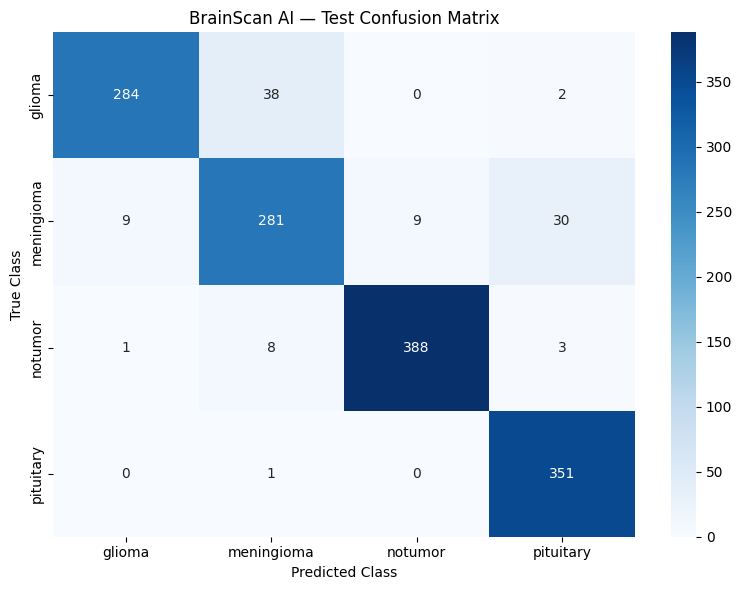

In [26]:
best_model = tf.keras.models.load_model(
    "/content/brainscan_model_v2.keras"
)

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("BrainScan AI — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Training History and Overfitting Analysis

We compare training and validation accuracy and loss across epochs.
A growing gap between training and validation performance can indicate overfitting.

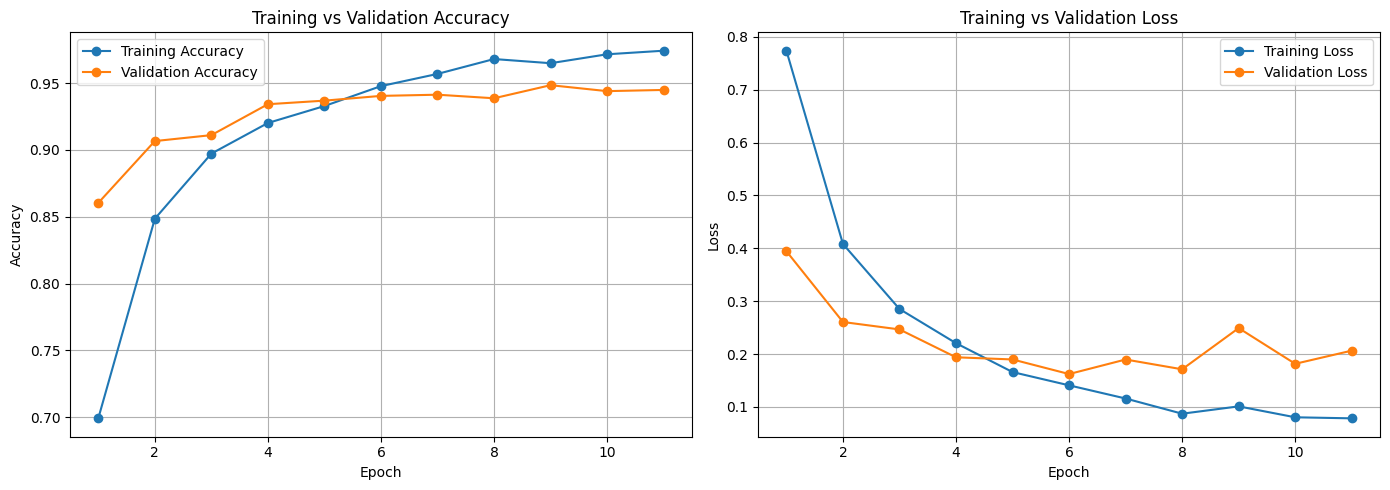

In [29]:
import matplotlib.pyplot as plt

history_data = history.history
epochs = range(1, len(history_data["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(epochs, history_data["accuracy"], marker="o",
             label="Training Accuracy")
axes[0].plot(epochs, history_data["val_accuracy"], marker="o",
             label="Validation Accuracy")
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss
axes[1].plot(epochs, history_data["loss"], marker="o",
             label="Training Loss")
axes[1].plot(epochs, history_data["val_loss"], marker="o",
             label="Validation Loss")
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Model Evaluation on the Test Set

The test set contains images that were not used to train the model or select the best epoch. We use it to measure how well the trained CNN generalizes to unseen images.

We will calculate the test loss and accuracy, then analyze its predictions using a classification report and confusion matrix.

In [31]:
# Load the saved best model
best_model = tf.keras.models.load_model(
    "/content/brainscan_model_v2.keras"
)

# Evaluate on the test set
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.9281 - loss: 0.2190
Test Loss: 0.2190
Test Accuracy: 92.81%


176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step
              precision    recall  f1-score   support

      glioma     0.9660    0.8765    0.9191       324
  meningioma     0.8567    0.8541    0.8554       329
     notumor     0.9773    0.9700    0.9737       400
   pituitary     0.9093    0.9972    0.9512       352

    accuracy                         0.9281      1405
   macro avg     0.9273    0.9245    0.9248      1405
weighted avg     0.9294    0.9281    0.9278      1405



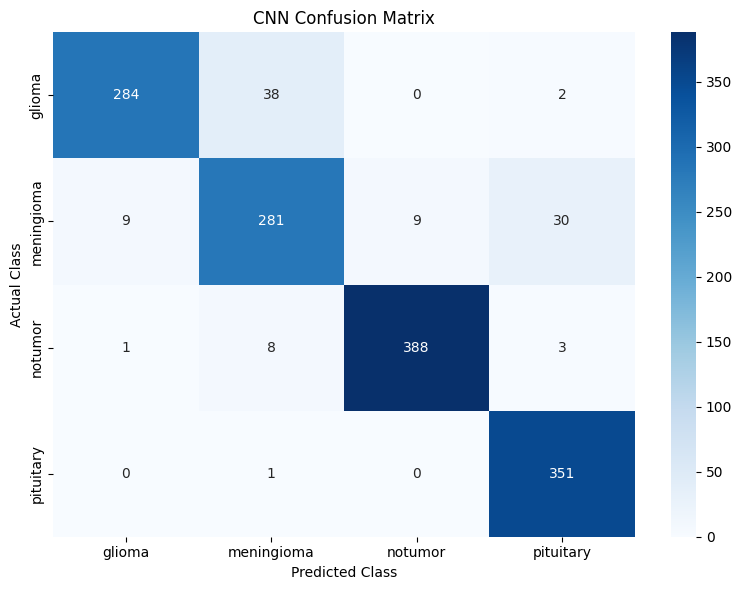

In [32]:
# Get predicted probabilities for each class
y_prob = best_model.predict(test_ds)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Get the actual labels in the same order as test_ds
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])

# Class names in LabelEncoder order
class_names = label_encoder.classes_

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN Confusion Matrix")
plt.tight_layout()
plt.show()

### Error Analysis

We inspect images that the CNN classified incorrectly. This helps us identify confusing patterns between tumor classes and decide how to improve the model.

Incorrect predictions: 101


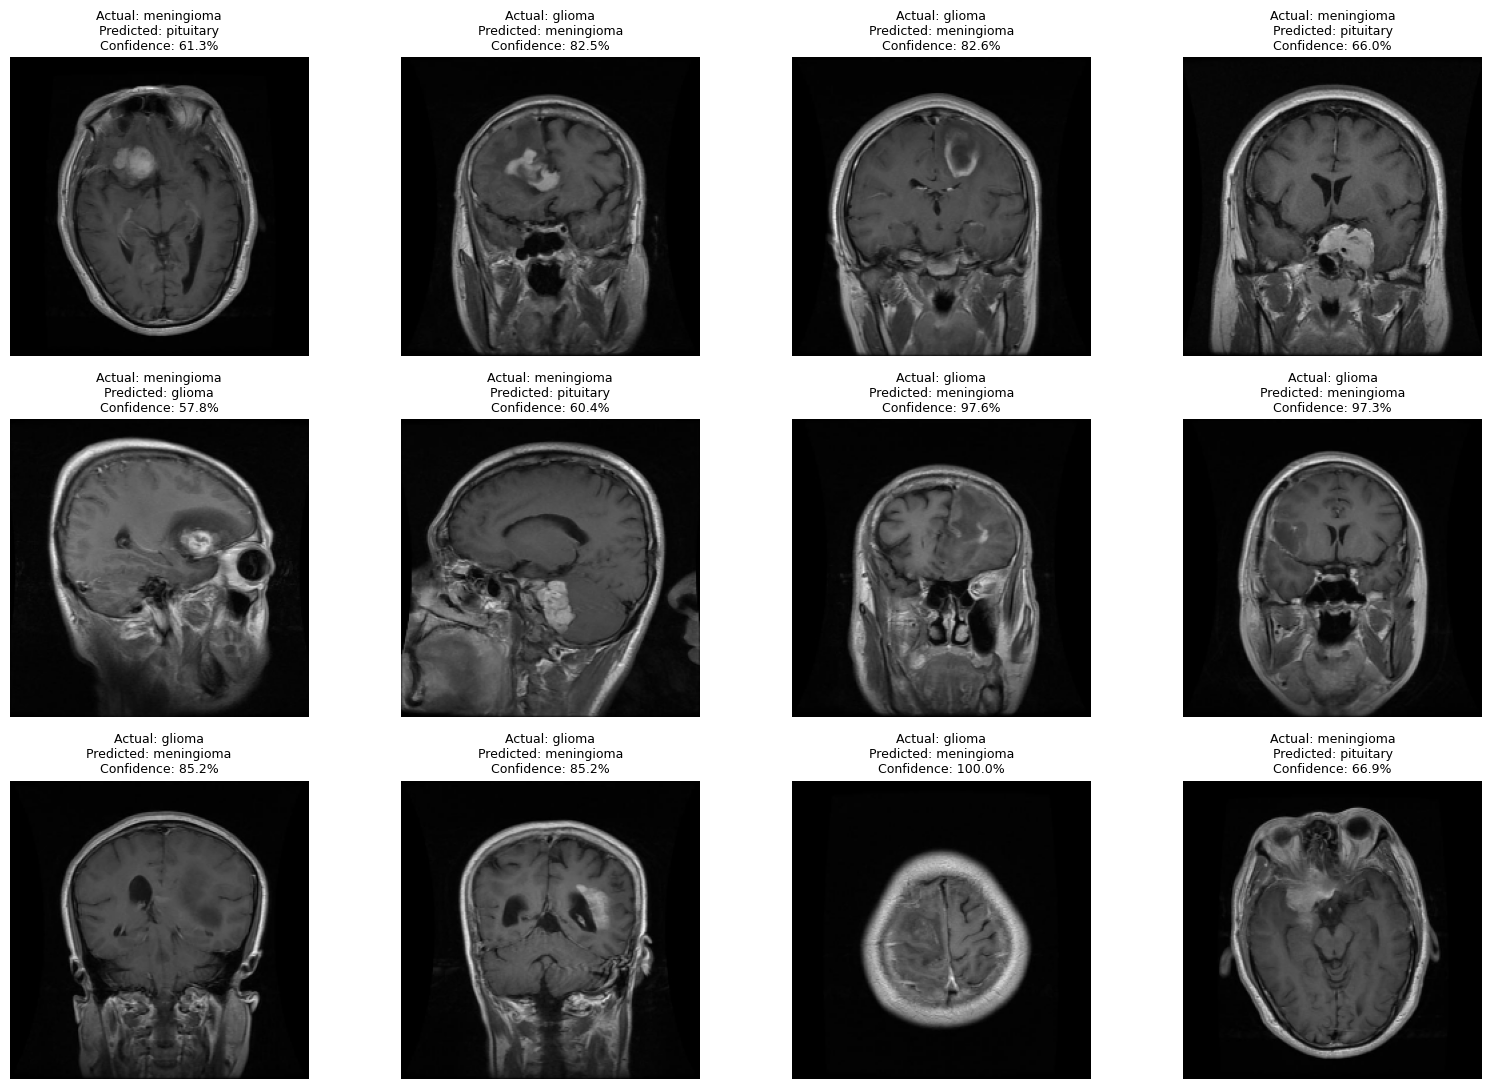

In [33]:
# Find the indices of incorrectly classified images
wrong_indices = np.where(y_true != y_pred)[0]

print("Incorrect predictions:", len(wrong_indices))

# Display up to 12 misclassified images
n_images = min(12, len(wrong_indices))

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i in range(n_images):
    idx = wrong_indices[i]

    actual = class_names[y_true[idx]]
    predicted = class_names[y_pred[idx]]
    confidence = y_prob[idx].max() * 100

    axes[i].imshow(X_test[idx])
    axes[i].set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1f}%",
        fontsize=9
    )
    axes[i].axis("off")

for i in range(n_images, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [34]:
# Show only incorrect predictions
errors_df = pd.DataFrame({
    "Actual": [class_names[i] for i in y_true[wrong_indices]],
    "Predicted": [class_names[i] for i in y_pred[wrong_indices]]
})

error_counts = (
    errors_df
    .value_counts()
    .reset_index(name="Number of Errors")
    .sort_values("Number of Errors", ascending=False)
)

display(error_counts)

,Actual,Predicted,Number of Errors
0,glioma,meningioma,38
1,meningioma,pituitary,30
2,meningioma,glioma,9
3,meningioma,notumor,9
4,notumor,meningioma,8
5,notumor,pituitary,3
6,glioma,pituitary,2
7,notumor,glioma,1
8,pituitary,meningioma,1


## Experiment 2: CNN with Data Augmentation

We add random image transformations to help the CNN learn more robust features and potentially reduce overfitting. We will compare this model with the original CNN.

In [36]:
tf.keras.backend.clear_session()

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
], name="data_augmentation")

model_aug = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(4, activation="softmax")
])

model_aug.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the Model

We use Adam to optimize the weights and sparse categorical cross-entropy because our four classes are represented by integer labels.

In [37]:
model_aug.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Configure Callbacks

ModelCheckpoint saves the model with the lowest validation loss. EarlyStopping stops training when validation loss stops improving and restores the best weights.

In [38]:
checkpoint_aug = tf.keras.callbacks.ModelCheckpoint(
    "/content/brainscan_model_augmented.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min",
    verbose=1
)

early_stopping_aug = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

### Train the Augmented CNN

Train the model using the existing training and validation datasets. Augmentation is applied during training, not during validation or prediction.

In [39]:
history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[checkpoint_aug, early_stopping_aug]
)

Epoch 1/20
562/562 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5022 - loss: 1.0963
Epoch 1: val_loss improved from None to 0.58167, saving model to /content/brainscan_model_augmented.keras

Epoch 1: finished saving model to /content/brainscan_model_augmented.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 28s 37ms/step - accuracy: 0.6086 - loss: 0.9421 - val_accuracy: 0.7794 - val_loss: 0.5817
Epoch 2/20
561/562 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7388 - loss: 0.6915
Epoch 2: val_loss improved from 0.58167 to 0.56239, saving model to /content/brainscan_model_augmented.keras

Epoch 2: finished saving model to /content/brainscan_model_augmented.keras
562/562 ━━━━━━━━━━━━━━━━━━━━ 20s 36ms/step - accuracy: 0.7365 - loss: 0.6888 - val_accuracy: 0.7767 - val_loss: 0.5624
Epoch 3/20
561/562 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7672 - loss: 0.5942
Epoch 3: val_loss improved from 0.56239 to 0.42023, saving model to /content/brainscan_model_augmented.keras

Epoch 3: finished saving

### Visualize Training Performance

Plot accuracy and loss to observe learning progress and possible overfitting.

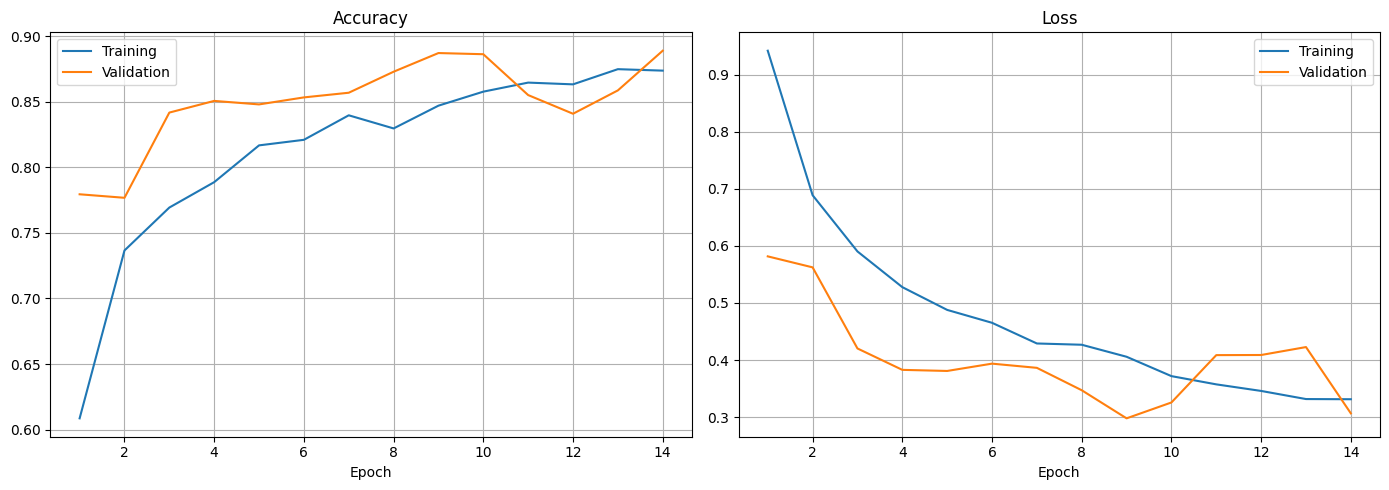

In [40]:
epochs = range(1, len(history_aug.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history_aug.history["accuracy"], label="Training")
axes[0].plot(epochs, history_aug.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history_aug.history["loss"], label="Training")
axes[1].plot(epochs, history_aug.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Evaluate the Augmented CNN

Evaluate the best saved model on the test set to measure its performance on unseen images.

In [41]:
best_model_aug = tf.keras.models.load_model(
    "/content/brainscan_model_augmented.keras"
)

test_loss_aug, test_accuracy_aug = best_model_aug.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss_aug:.4f}")
print(f"Test Accuracy: {test_accuracy_aug:.2%}")

176/176 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8811 - loss: 0.3119
Test Loss: 0.3119
Test Accuracy: 88.11%


### Classification Report and Confusion Matrix

Analyze precision, recall, F1-score, and classification errors for each class.

176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
              precision    recall  f1-score   support

      glioma     0.9650    0.7654    0.8537       324
  meningioma     0.7726    0.7538    0.7631       329
     notumor     0.9272    0.9875    0.9564       400
   pituitary     0.8653    0.9858    0.9216       352

    accuracy                         0.8811      1405
   macro avg     0.8825    0.8731    0.8737      1405
weighted avg     0.8842    0.8811    0.8787      1405



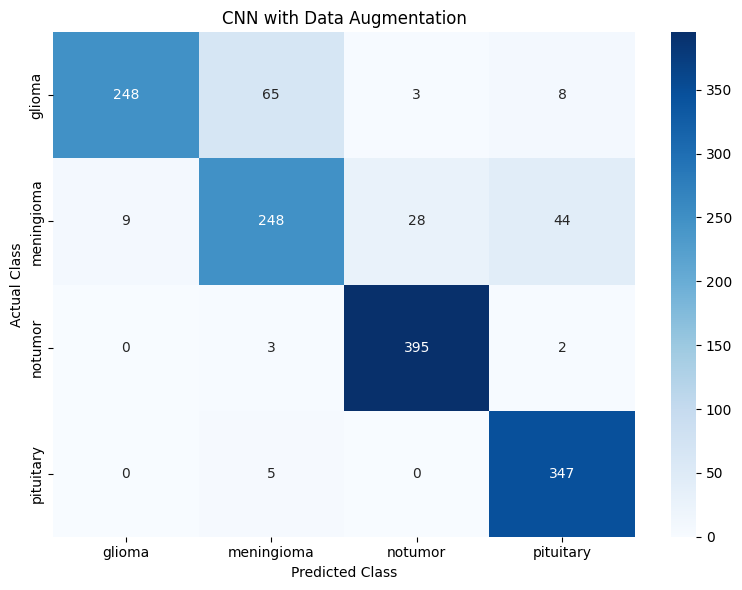

In [42]:
y_prob_aug = best_model_aug.predict(test_ds)
y_pred_aug = np.argmax(y_prob_aug, axis=1)

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

class_names = label_encoder.classes_

print(classification_report(
    y_true,
    y_pred_aug,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4
))

cm_aug = confusion_matrix(y_true, y_pred_aug)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_aug,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("CNN with Data Augmentation")
plt.tight_layout()
plt.show()

### Compare Both Models

Compare the augmented CNN with the original baseline. Accuracy and loss are useful, but class-level recall and confusion patterns also matter.

In [43]:
comparison_df = pd.DataFrame({
    "Model": ["Original CNN", "CNN with Augmentation"],
    "Test Accuracy": [0.9281, test_accuracy_aug],
    "Test Loss": [0.2190, test_loss_aug]
})

display(comparison_df.style.format({
    "Test Accuracy": "{:.2%}",
    "Test Loss": "{:.4f}"
}))

,Model,Test Accuracy,Test Loss
0,Original CNN,92.81%,0.2190
1,CNN with Augmentation,88.11%,0.3119
